# 06 - Sequence Model (1D-CNN) and Comparison
A second, independent route to the same problem. Instead of summarising each
location's 42-year record into 81 hand-crafted features, this feeds the **raw
sequence** to a 1D convolutional network and lets it learn its own
representation.

**Reads:** `processed/madrid_cube2.pkl`, `amsterdam_cube2.pkl`, `*_px.parquet`,
`final_results.csv` (for the comparison at the end)
**Writes:** `processed/cnn_results.csv`, `cnn_comparison.csv`, `cnn_madrid.pt`
**Standalone:** does not need notebooks 04 or 05 in memory.

## The question
Our feature pipeline makes a choice: 42 years x 6 bands becomes 81 summary
statistics. That is a compression, and compression discards something. The
question is whether what it discards matters.

Three things get measured, and the first one needs no neural network at all:

| test | what it answers |
|---|---|
| raw sequence -> Random Forest | does summarising lose signal? |
| 1D-CNN on Madrid | can a sequence model read the raw record better? |
| CNN embedding + prototypes | does a *learned* space transfer better than a hand-built one? |

Sections: 1) setup, 2) raw sequences, 3) per-domain standardisation,
4) spatial split, 5) does summarising lose signal, 6) the network,
7) train, 8) Madrid score, 9) transfer, 10) five sample sizes, 11) verdict.

## 1. Setup

In [1]:
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

OUT_DIR = "processed"
SEED = 42
CLASSES = [1, 2, 3, 4]
SHOTS = [5, 25, 50, 100, 200]
N_SEED = 10
EVAL_FRAC = 0.40
BANDS = ["Blue", "Green", "Red", "NIR", "SWIR1", "SWIR2"]
print("OK - ready")

OK - ready


In [18]:
import sys
!{sys.executable} -m pip install torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 554.6/554.6 MB 16.8 MB/s  0:00:32m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 553.1/553.1 MB 14.0 MB/s  0:00:35m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 15.3 MB/s  0:00:11m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.0/216.0 MB 16.7 MB/s  0:00:12m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 17.3 MB/s  0:00:03m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 16.8 MB/s  0:00:00m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 MB 12.5 MB/s  0:00:29m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 9.6 MB/s  0:00:016m0:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 MB 6.4 MB/s  0:00:14m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 4.5 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 214.1/214.1 MB 8.2 MB/s  0:00:26m0:00:0100:01
   ━━━━━━━━━━━━━━━

### Is torch available?
If not, the notebook falls back to a plain feed-forward network in scikit-learn. The comparison still works; only the convolution is lost.

In [19]:
try:
    import torch
    import torch.nn as nn
    HAS_TORCH = True
    torch.manual_seed(SEED)
    print(f"torch {torch.__version__}   threads = {torch.get_num_threads()}")
except ImportError:
    HAS_TORCH = False
    print("torch NOT available - will use sklearn MLPClassifier instead")

torch 2.14.1+cu130   threads = 16


## 2. Raw sequences
The cleaned cubes from notebook 02, reshaped to (locations, 6 bands, 42 years). No summarising.

In [20]:
madrid_px = pd.read_parquet(f"{OUT_DIR}/madrid_px.parquet")
amsterdam_px = pd.read_parquet(f"{OUT_DIR}/amsterdam_px.parquet")
madrid_cube2 = pd.read_pickle(f"{OUT_DIR}/madrid_cube2.pkl")
amsterdam_cube2 = pd.read_pickle(f"{OUT_DIR}/amsterdam_cube2.pkl")
print("cubes loaded")

cubes loaded


In [21]:
def cube_to_array(cube, px):
    """(n_locations, 6 bands, 42 years), plus aligned labels and years."""
    idx = cube[BANDS[0]].index
    S = np.stack([cube[b].reindex(idx).to_numpy("float32") for b in BANDS], axis=1)
    y = px["age_class"].reindex(idx).to_numpy()
    yr = px["weighted_mean_year"].reindex(idx).to_numpy("float32")
    return S, y, yr, idx

SEQ_M, ym, yearm, IDX_M = cube_to_array(madrid_cube2, madrid_px)
SEQ_A, ya, yeara, IDX_A = cube_to_array(amsterdam_cube2, amsterdam_px)
print("madrid   ", SEQ_M.shape)
print("amsterdam", SEQ_A.shape)
print("non-finite:", int(~np.isfinite(SEQ_M).all()), int(~np.isfinite(SEQ_A).all()))

madrid    (76263, 6, 42)
amsterdam (25992, 6, 42)
non-finite: 0 0


## 3. Per-domain standardisation
Each city is standardised against **its own** mean and spread, per band. This is
the same free, label-free adaptation that gave +0.024 on the engineered features
(notebook 05) - applied here to the raw sequence before the network ever sees it.

Doing it per city matters: a network trained on Madrid's absolute brightness
would learn Madrid's brightness, and our EDA showed that absolute level is the
single strongest city fingerprint (1.37 SD apart between the cities).

In [22]:
def seq_scale(S):
    mu = S.mean(axis=(0, 2), keepdims=True)
    sd = S.std(axis=(0, 2), keepdims=True) + 1e-6
    return ((S - mu) / sd).astype("float32"), mu, sd

SEQ_M_Z, mu_m, sd_m = seq_scale(SEQ_M)
SEQ_A_Z, mu_a, sd_a = seq_scale(SEQ_A)

print("band          madrid mean   amsterdam mean   (raw, before scaling)")
for i, b in enumerate(BANDS):
    print(f"  {b:6s}    {mu_m[0,i,0]:10.0f}     {mu_a[0,i,0]:10.0f}")
print("\nAfter scaling both are centred at 0 with unit spread, per band.")

band          madrid mean   amsterdam mean   (raw, before scaling)
  Blue           10627           9413
  Green          11592           9942
  Red            12734          10268
  NIR            15384          13656
  SWIR1          16084          13137
  SWIR2          14701          11762

After scaling both are centred at 0 with unit spread, per band.


## 4. Spatial split
Neighbouring 30 m locations often cover the same building. We reserve whole
spatial blocks for evaluation, so a training location's neighbours can never
appear in the test set - and the evaluation set is the **same** at every sample
size, which keeps the F1-vs-n curve comparable point to point.

In [23]:
def spatial_blocks(index, size=20):
    px = index.get_level_values("px_key").to_numpy()
    py = index.get_level_values("py_key").to_numpy()
    return pd.factorize((px // size) * 100000 + (py // size))[0]

BLOCKS_M = spatial_blocks(IDX_M)
BLOCKS_A = spatial_blocks(IDX_A)

_rng0 = np.random.default_rng(SEED)
_all = np.unique(BLOCKS_A)
_eval_blocks = _rng0.choice(_all, size=int(EVAL_FRAC * len(_all)), replace=False)
EVAL_IDX = np.where(np.isin(BLOCKS_A, _eval_blocks))[0]
POOL_IDX = np.where(~np.isin(BLOCKS_A, _eval_blocks))[0]

print(f"Madrid blocks    : {len(np.unique(BLOCKS_M)):,}")
print(f"Amsterdam blocks : {len(_all):,}  ->  {len(_eval_blocks):,} eval, "
      f"{len(_all)-len(_eval_blocks):,} pool")
print(f"Amsterdam locations: {len(EVAL_IDX):,} eval, {len(POOL_IDX):,} pool")
print("\nclass   pool    eval")
for c in CLASSES:
    print(f"  {c}    {int((ya[POOL_IDX]==c).sum()):6,}  {int((ya[EVAL_IDX]==c).sum()):6,}")

Madrid blocks    : 965
Amsterdam blocks : 526  ->  210 eval, 316 pool
Amsterdam locations: 10,998 eval, 14,994 pool

class   pool    eval
  1     4,007   3,561
  2     5,389   3,413
  3     3,699   3,046
  4     1,899     978


In [24]:
def _sample(n, seed):
    """n labelled locations per class, drawn from the POOL blocks only."""
    rng = np.random.default_rng(seed)
    train = np.concatenate([
        rng.choice(POOL_IDX[ya[POOL_IDX] == c],
                   size=min(n, int((ya[POOL_IDX] == c).sum())), replace=False)
        for c in CLASSES])
    return train, EVAL_IDX

def _nearest(Z, protos):
    return np.array(CLASSES)[((Z[:, None, :] - protos[None]) ** 2).sum(-1).argmin(1)]

print("OK - defined: _sample, _nearest")

OK - defined: _sample, _nearest


## 5. First: does summarising actually lose signal?
This needs no neural network. Flatten the raw sequence to 252 numbers
(6 bands x 42 years) and give it to the same Random Forest we used on the 81
engineered features.

- If **raw wins**, our features are discarding something and a sequence model is justified.
- If **raw loses**, the feature engineering is doing real work and the case for a CNN weakens.

Either answer is a result. Three-fold spatial CV to keep it quick.

In [25]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, GroupKFold, GroupShuffleSplit
from sklearn.metrics import make_scorer, f1_score, confusion_matrix

macro = make_scorer(f1_score, average="macro")

def make_rf():
    return RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                  n_jobs=-1, random_state=SEED)
print("OK - defined: make_rf")

OK - defined: make_rf


In [26]:
t = time.time()
RAW_M = SEQ_M_Z.reshape(len(SEQ_M_Z), -1)          # 76,263 x 252
sc_raw = cross_val_score(make_rf(), RAW_M, ym, cv=GroupKFold(3),
                         groups=BLOCKS_M, scoring=macro, n_jobs=-1)
print(f"raw 252-value sequence -> RF : {sc_raw.mean():.4f} +/- {sc_raw.std():.4f}"
      f"   ({time.time()-t:.0f}s)")
print(f"81 engineered features -> RF : 0.6032   (notebook 04, 5 spatial folds)")

raw 252-value sequence -> RF : 0.6123 +/- 0.0144   (54s)
81 engineered features -> RF : 0.6032   (notebook 04, 5 spatial folds)


## 6. The network
Deliberately small. The point is a fair comparison, not a maximised model - and
a large network trained on Madrid would memorise Madrid, which is exactly the
failure mode the earlier notebooks diagnosed (LDA and prototype shrinkage both
*hurt* transfer because they imported Madrid's class structure).

Convolutions run along the **time** axis, so the filters learn temporal shapes:
a step, a ramp, a spike. The penultimate layer is a 32-dimensional embedding,
which section 9 uses for prototype transfer.

In [27]:
if HAS_TORCH:
    class TinyCNN(nn.Module):
        def __init__(self, n_bands=6, n_classes=4, emb=32):
            super().__init__()
            self.features = nn.Sequential(
                nn.Conv1d(n_bands, 32, 5, padding=2), nn.ReLU(), nn.BatchNorm1d(32),
                nn.MaxPool1d(2),
                nn.Conv1d(32, 64, 3, padding=1), nn.ReLU(), nn.BatchNorm1d(64),
                nn.MaxPool1d(2),
                nn.Conv1d(64, 64, 3, padding=1), nn.ReLU(), nn.BatchNorm1d(64),
                nn.AdaptiveAvgPool1d(1),
            )
            self.embed = nn.Sequential(nn.Flatten(), nn.Linear(64, emb), nn.ReLU())
            self.head = nn.Linear(emb, n_classes)

        def forward(self, x, return_embedding=False):
            z = self.embed(self.features(x))
            return z if return_embedding else self.head(z)

    n_par = sum(p.numel() for p in TinyCNN().parameters())
    print(f"OK - defined: TinyCNN  ({n_par:,} parameters)")
else:
    from sklearn.neural_network import MLPClassifier
    print("OK - will use MLPClassifier")

OK - defined: TinyCNN  (22,084 parameters)


In [28]:
EPOCHS = 12
BATCH = 512

def train_cnn(S, y, epochs=EPOCHS, verbose=True):
    """Train on (sequences, labels). Class-weighted, matching the forests."""
    X_t = torch.tensor(S)
    y_t = torch.tensor(y - 1, dtype=torch.long)
    counts = np.bincount(y - 1, minlength=4)
    w = torch.tensor(len(y) / (4 * np.maximum(counts, 1)), dtype=torch.float32)

    net = TinyCNN()
    opt = torch.optim.Adam(net.parameters(), lr=3e-3)
    lossf = nn.CrossEntropyLoss(weight=w)
    n, t0 = len(X_t), time.time()

    for ep in range(epochs):
        net.train()
        perm = torch.randperm(n)
        tot = 0.0
        for i in range(0, n, BATCH):
            idx = perm[i:i+BATCH]
            opt.zero_grad()
            loss = lossf(net(X_t[idx]), y_t[idx])
            loss.backward(); opt.step()
            tot += loss.item() * len(idx)
        if verbose:
            print(f"  epoch {ep+1:2d}/{epochs}  loss {tot/n:.4f}  ({time.time()-t0:.0f}s)")
    net.eval()
    return net

def embed_and_logits(net, S, batch=4096):
    outs, embs = [], []
    with torch.no_grad():
        for i in range(0, len(S), batch):
            x = torch.tensor(S[i:i+batch])
            embs.append(net(x, return_embedding=True).numpy())
            outs.append(net(x).numpy())
    return np.vstack(embs), np.vstack(outs)

if HAS_TORCH:
    print("OK - defined: train_cnn, embed_and_logits")

OK - defined: train_cnn, embed_and_logits


## 7. Train on Madrid
The slow cell. Watch the loss fall - if it plateaus immediately something is wrong.

In [29]:
if HAS_TORCH:
    net_full = train_cnn(SEQ_M_Z, ym)
    EMB_M, _ = embed_and_logits(net_full, SEQ_M_Z)
    EMB_A, LOGIT_A = embed_and_logits(net_full, SEQ_A_Z)
    torch.save(net_full.state_dict(), f"{OUT_DIR}/cnn_madrid.pt")
    print(f"\nembeddings: madrid {EMB_M.shape}, amsterdam {EMB_A.shape}")
    print("saved:", f"{OUT_DIR}/cnn_madrid.pt")
else:
    mlp = MLPClassifier(hidden_layer_sizes=(128, 32), max_iter=200,
                        random_state=SEED, early_stopping=True)
    t0 = time.time()
    mlp.fit(SEQ_M_Z.reshape(len(SEQ_M_Z), -1), ym)
    LOGIT_A = mlp.predict_proba(SEQ_A_Z.reshape(len(SEQ_A_Z), -1))
    EMB_M = EMB_A = None
    print(f"MLP trained in {time.time()-t0:.0f}s")

  epoch  1/12  loss 0.9833  (2s)
  epoch  2/12  loss 0.8764  (3s)
  epoch  3/12  loss 0.8374  (5s)
  epoch  4/12  loss 0.8103  (7s)
  epoch  5/12  loss 0.7880  (9s)
  epoch  6/12  loss 0.7698  (10s)
  epoch  7/12  loss 0.7533  (12s)
  epoch  8/12  loss 0.7405  (14s)
  epoch  9/12  loss 0.7282  (15s)
  epoch 10/12  loss 0.7154  (17s)
  epoch 11/12  loss 0.7041  (19s)
  epoch 12/12  loss 0.6907  (21s)

embeddings: madrid (76263, 32), amsterdam (25992, 32)
saved: processed/cnn_madrid.pt


## 8. Madrid score, honestly split
Trained on 75% of the spatial blocks, scored on the other 25%. Directly
comparable with the 0.6032 from notebook 04.

In [30]:
if HAS_TORCH:
    tr, te = next(GroupShuffleSplit(1, test_size=0.25, random_state=SEED)
                  .split(SEQ_M_Z, ym, groups=BLOCKS_M))
    net_cv = train_cnn(SEQ_M_Z[tr], ym[tr], verbose=False)
    _, logit_te = embed_and_logits(net_cv, SEQ_M_Z[te])
    f1_cnn_madrid = f1_score(ym[te], logit_te.argmax(1) + 1, average="macro")
else:
    f1_cnn_madrid = np.nan

print("MADRID, held-out spatial blocks")
print(f"  RF on 81 engineered features : 0.6032   (notebook 04)")
print(f"  RF on raw 252 values         : {sc_raw.mean():.4f}")
print(f"  CNN on raw sequence          : {f1_cnn_madrid:.4f}")

MADRID, held-out spatial blocks
  RF on 81 engineered features : 0.6032   (notebook 04)
  RF on raw 252 values         : 0.6123
  CNN on raw sequence          : 0.6450


## 9. Transfer to Amsterdam
Two routes, both using the fixed evaluation set from section 4.

- **cnn_zero_shot** - the Madrid network applied directly, no Amsterdam labels.
- **cnn_proto** - prototype transfer inside the network's learned 32-dimensional
  embedding. The network supplies the space; the few labels supply the class
  centres. This is the metric-learning approach the organisers suggested, with a
  learned representation instead of a hand-built one.

In [31]:
def run_cnn(method="cnn_proto", n_per_class=25, seed=0):
    train, test = _sample(n_per_class, seed)

    if method == "cnn_zero_shot":
        pred = LOGIT_A[test].argmax(1) + 1
    elif method == "cnn_proto":
        Z = (EMB_A - EMB_A.mean(0)) / (EMB_A.std(0) + 1e-6)      # per-domain
        protos = np.stack([Z[train][ya[train] == c].mean(0) for c in CLASSES])
        pred = _nearest(Z[test], protos)
    else:
        raise ValueError(method)

    true = ya[test]
    cm = confusion_matrix(true, pred, labels=CLASSES).astype(float)
    return dict(f1=f1_score(true, pred, average="macro"),
                per_class=f1_score(true, pred, average=None, labels=CLASSES),
                cm=cm / cm.sum(1, keepdims=True), n_test=len(test))
print("OK - defined: run_cnn")

OK - defined: run_cnn


In [32]:
for m in ["cnn_zero_shot", "cnn_proto"]:
    scores = [run_cnn(m, 25, seed=s)["f1"] for s in range(3)]
    print(f"  {m:16s} {np.mean(scores):.4f} +/- {np.std(scores):.4f}")
print("\nfeature-based reference at 25/class: see processed/final_results.csv")

  cnn_zero_shot    0.3261 +/- 0.0000
  cnn_proto        0.5120 +/- 0.0096

feature-based reference at 25/class: see processed/final_results.csv


## 10. Five sample sizes
One cell per size, saving as it goes.

In [33]:
cnn_results = []

def sweep_cnn(n):
    for m in ["cnn_proto", "cnn_zero_shot"]:
        t = time.time()
        scores = [run_cnn(m, n, seed=s)["f1"] for s in range(N_SEED)]
        cnn_results.append({"method": m, "n": n,
                            "mean": np.mean(scores), "std": np.std(scores)})
        print(f"  {m:16s} n={n:3d}  {np.mean(scores):.4f} +/- {np.std(scores):.4f}"
              f"   ({time.time()-t:.0f}s)")
    pd.DataFrame(cnn_results).to_csv(f"{OUT_DIR}/cnn_results.csv", index=False)
print("OK - defined: sweep_cnn")

OK - defined: sweep_cnn


In [34]:
sweep_cnn(5)

  cnn_proto        n=  5  0.4365 +/- 0.0416   (0s)
  cnn_zero_shot    n=  5  0.3261 +/- 0.0000   (0s)


In [35]:
sweep_cnn(25)

  cnn_proto        n= 25  0.4993 +/- 0.0209   (0s)
  cnn_zero_shot    n= 25  0.3261 +/- 0.0000   (0s)


In [36]:
sweep_cnn(50)

  cnn_proto        n= 50  0.5113 +/- 0.0167   (0s)
  cnn_zero_shot    n= 50  0.3261 +/- 0.0000   (0s)


In [37]:
sweep_cnn(100)

  cnn_proto        n=100  0.5124 +/- 0.0065   (0s)
  cnn_zero_shot    n=100  0.3261 +/- 0.0000   (0s)


In [38]:
sweep_cnn(200)

  cnn_proto        n=200  0.5266 +/- 0.0083   (0s)
  cnn_zero_shot    n=200  0.3261 +/- 0.0000   (0s)


## 11. The verdict
Feature-based against sequence-based, on identical splits and seeds.

In [39]:
cnn_res = pd.DataFrame(cnn_results)

try:
    feat_res = pd.read_csv(f"{OUT_DIR}/final_results.csv")
    both = pd.concat([feat_res[["method", "n", "mean", "std"]], cnn_res])
except FileNotFoundError:
    both = cnn_res
    print("note: final_results.csv not found - showing CNN results only")

pivot = both.pivot_table(index="n", columns="method", values="mean").round(4)
pivot.to_csv(f"{OUT_DIR}/cnn_comparison.csv")
print(pivot.to_string())

method  cnn_proto  cnn_zero_shot  proto_da_shrink  prototype
n                                                           
5          0.4365         0.3261           0.4882     0.4431
25         0.4993         0.3261           0.5605     0.5234
50         0.5113         0.3261           0.5651     0.5240
100        0.5124         0.3261           0.5714     0.5344
200        0.5266         0.3261           0.5766     0.5441


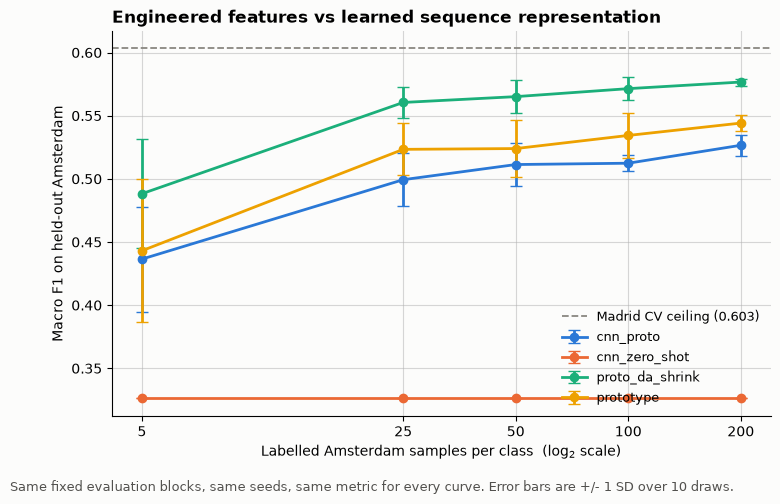

In [40]:
INK2, SURF = "#52514e", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF,
                     "font.size": 10, "legend.frameon": False,
                     "axes.spines.top": False, "axes.spines.right": False})

palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#4a3aa7"]
fig, ax = plt.subplots(figsize=(8.5, 5))
for (m, d), colour in zip(both.groupby("method"), palette):
    d = d.sort_values("n")
    ax.errorbar(np.log2(d["n"]), d["mean"], yerr=d["std"],
                marker="o", ms=6, lw=2, capsize=4, color=colour, label=m)

ax.axhline(0.6032, ls="--", lw=1.3, color="#898781", label="Madrid CV ceiling (0.603)")
ax.set_xticks(np.log2(SHOTS), [str(n) for n in SHOTS])
ax.set_xlabel("Labelled Amsterdam samples per class  (log$_2$ scale)")
ax.set_ylabel("Macro F1 on held-out Amsterdam")
ax.set_title("Engineered features vs learned sequence representation",
             loc="left", fontweight="bold")
ax.grid(alpha=0.5); ax.set_axisbelow(True)
ax.legend(loc="lower right", fontsize=9)
fig.text(0.005, -0.04,
         "Same fixed evaluation blocks, same seeds, same metric for every curve. "
         "Error bars are +/- 1 SD over 10 draws.",
         fontsize=9, color=INK2, ha="left")
plt.show()

### What to write up
Whatever the numbers say, including if the CNN loses. Three specific claims to
check against the output:

1. **Does summarising lose signal?** Section 5 answers it directly - raw 252
   against 81 engineered, same model, same folds.
2. **Does a sequence model read Madrid better?** Section 8.
3. **Does a learned space transfer better than a hand-built one?** Section 11.
   This is the one that matters most: our earlier finding was that anything
   importing Madrid's *class structure* hurt transfer, while anything adjusting
   only *feature distributions* helped. A CNN embedding is a learned class
   structure, so if the principle holds it should transfer worse, not better.